In [5]:
import sys  # Check the Python interpreter being used
import pandapower as pp  # Power-system modelling
import simbench as sb  # Benchmark grid data

print(sys.version)
print("pandapower:", pp.__version__)
print("simbench:", sb.__version__)

3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
pandapower: 3.5.5
simbench: 1.6.3


In [7]:
import pandas as pd  # Work with network tables and profile data
import pandapower as pp  # Represent and solve electrical power networks
import simbench as sb  # Load realistic benchmark grid networks

SIMBENCH_CODE = "1-MVLV-urban-all-0-sw"  # Urban MV grid with connected LV networks

print("Selected network:", SIMBENCH_CODE)

Selected network: 1-MVLV-urban-all-0-sw


In [8]:
net = sb.get_simbench_net(
    SIMBENCH_CODE
)  # Load the complete benchmark network

print("Network loaded successfully.")
print("Network type:", type(net))

Network loaded successfully.
Network type: <class 'pandapower.auxiliary.pandapowerNet'>


In [9]:
print("\n--- DIGITAL TWIN GRID SUMMARY ---")

print("Buses        :", len(net.bus))
print("Lines        :", len(net.line))
print("Transformers :", len(net.trafo))
print("Loads        :", len(net.load))
print("Generators   :", len(net.sgen))
print("Storage      :", len(net.storage))
print("Switches     :", len(net.switch))
print("External Grid:", len(net.ext_grid))


--- DIGITAL TWIN GRID SUMMARY ---
Buses        : 10458
Lines        : 10328
Transformers : 135
Loads        : 11542
Generators   : 806
Storage      : 0
Switches     : 20933
External Grid: 1


In [10]:
voltage_levels = (
    net.bus["vn_kv"]
    .value_counts()
    .sort_index()
)  # Count buses at each nominal voltage

display(voltage_levels)

vn_kv
0.4      10314
10.0       142
110.0        2
Name: count, dtype: int64

In [11]:
display(
    net.bus[
        ["name", "vn_kv", "type", "zone", "in_service"]
    ].head(10)
)

,name,vn_kv,type,zone,in_service
0,LV3.301 Bus 1,0.4,b,NaN,True
1,LV3.301 Bus 50,0.4,b,NaN,True
2,LV3.301 Bus 61,0.4,b,NaN,True
3,LV3.301 Bus 72,0.4,b,NaN,True
4,LV3.301 Bus 83,0.4,b,NaN,True
5,LV3.301 Bus 94,0.4,b,NaN,True
6,LV3.301 Bus 115,0.4,b,NaN,True
7,LV3.301 Bus 126,0.4,b,NaN,True
8,LV3.301 Bus 2,0.4,b,NaN,True
9,LV3.301 Bus 13,0.4,b,NaN,True


In [12]:
line_columns = [
    "name",
    "from_bus",
    "to_bus",
    "length_km",
    "max_i_ka",
    "in_service",
]

display(net.line[line_columns].head(10))

,name,from_bus,to_bus,length_km,max_i_ka,in_service
0,LV3.301 Line 1,121,22,0.001334,0.27,True
1,LV3.301 Line 48,69,108,0.001545,0.27,True
2,LV3.301 Line 59,4,102,0.008770,0.27,True
3,LV3.301 Line 70,16,96,0.007663,0.27,True
4,LV3.301 Line 81,20,65,0.025899,0.27,True
5,LV3.301 Line 92,57,49,0.005759,0.27,True
6,LV3.301 Line 114,85,87,0.010480,0.27,True
7,LV3.301 Line 125,25,52,0.004915,0.27,True
8,LV3.301 Line 2,109,42,0.022687,0.27,True
9,LV3.301 Line 13,92,106,0.053218,0.27,True


In [13]:
trafo_columns = [
    "name",
    "hv_bus",
    "lv_bus",
    "sn_mva",
    "vn_hv_kv",
    "vn_lv_kv",
]

display(net.trafo[trafo_columns].head(10))

,name,hv_bus,lv_bus,sn_mva,vn_hv_kv,vn_lv_kv
0,MV3.101-LV3.301-Trafo,31061,104,0.4,10.0,0.4
1,MV3.101-LV3.302-Trafo,31062,488,0.4,10.0,0.4
2,MV3.101-LV3.303-Trafo,31063,872,0.4,10.0,0.4
3,MV3.101-LV3.304-Trafo,31067,1256,0.4,10.0,0.4
4,MV3.101-LV3.305-Trafo,31074,1640,0.4,10.0,0.4
5,MV3.101-LV3.306-Trafo,31076,2024,0.4,10.0,0.4
6,MV3.101-LV3.307-Trafo,31080,2408,0.4,10.0,0.4
7,MV3.101-LV3.308-Trafo,31083,2792,0.4,10.0,0.4
8,MV3.101-LV3.309-Trafo,31085,3176,0.4,10.0,0.4
9,MV3.101-LV4.301-Trafo 1,30953,3470,0.4,10.0,0.4


In [14]:
voltage_levels = (
    net.bus["vn_kv"]
    .value_counts()
    .sort_index()
)  # Count buses at every voltage level

display(voltage_levels)

vn_kv
0.4      10314
10.0       142
110.0        2
Name: count, dtype: int64

In [15]:
print("--- INSTALLED NETWORK POWER ---")

print(
    "Load active power     :",
    round(net.load["p_mw"].sum(), 3),
    "MW",
)

print(
    "Generator active power:",
    round(net.sgen["p_mw"].sum(), 3),
    "MW",
)

--- INSTALLED NETWORK POWER ---
Load active power     : 49.707 MW
Generator active power: 13.569 MW


In [18]:
print("Load table columns:")
print(net.load.columns.tolist())


Load table columns:
['name', 'bus', 'p_mw', 'q_mvar', 'const_z_p_percent', 'const_i_p_percent', 'const_z_q_percent', 'const_i_q_percent', 'sn_mva', 'scaling', 'in_service', 'type', 'max_q_mvar', 'min_p_mw', 'max_p_mw', 'min_q_mvar', 'voltLvl', 'subnet', 'profile']


In [19]:
display(net.load.head(15))

,name,bus,p_mw,q_mvar,const_z_p_percent,const_i_p_percent,const_z_q_percent,const_i_q_percent,sn_mva,scaling,in_service,type,max_q_mvar,min_p_mw,max_p_mw,min_q_mvar,voltLvl,subnet,profile
0,LV3.301 Load 1,112,0.003,0.001186,0.0,0.0,0.0,0.0,0.003226,1.0,True,NaN,NaN,NaN,NaN,NaN,7,LV3.301,H0-C
1,LV3.301 Load 31,22,0.002,0.000790,0.0,0.0,0.0,0.0,0.002151,1.0,True,NaN,NaN,NaN,NaN,NaN,7,LV3.301,H0-A
2,LV3.301 Load 42,32,0.002,0.000790,0.0,0.0,0.0,0.0,0.002151,1.0,True,NaN,NaN,NaN,NaN,NaN,7,LV3.301,H0-G
3,LV3.301 Load 53,81,0.002,0.000790,0.0,0.0,0.0,0.0,0.002151,1.0,True,NaN,NaN,NaN,NaN,NaN,7,LV3.301,H0-L
4,LV3.301 Load 64,86,0.002,0.000790,0.0,0.0,0.0,0.0,0.002151,1.0,True,NaN,NaN,NaN,NaN,NaN,7,LV3.301,H0-L
5,LV3.301 Load 75,23,0.002,0.000790,0.0,0.0,0.0,0.0,0.002151,1.0,True,NaN,NaN,NaN,NaN,NaN,7,LV3.301,H0-L
6,LV3.301 Load 86,75,0.003,0.001186,0.0,0.0,0.0,0.0,0.003226,1.0,True,NaN,NaN,NaN,NaN,NaN,7,LV3.301,H0-C
7,LV3.301 Load 97,17,0.008,0.003162,0.0,0.0,0.0,0.0,0.008602,1.0,True,NaN,NaN,NaN,NaN,NaN,7,LV3.301,G1-C
8,LV3.301 Load 108,35,0.002,0.000790,0.0,0.0,0.0,0.0,0.002151,1.0,True,NaN,NaN,NaN,NaN,NaN,7,LV3.301,H0-A
9,LV3.301 Load 2,116,0.003,0.001186,0.0,0.0,0.0,0.0,0.003226,1.0,True,NaN,NaN,NaN,NaN,NaN,7,LV3.301,H0-C


In [20]:
print("Generator table columns:")
print(net.sgen.columns.tolist())
display(net.sgen.head(15))

Generator table columns:
['name', 'bus', 'p_mw', 'q_mvar', 'min_q_mvar', 'max_q_mvar', 'sn_mva', 'scaling', 'controllable', 'id_q_capability_characteristic', 'reactive_capability_curve', 'curve_style', 'in_service', 'type', 'current_source', 'slack_weight', 'min_p_mw', 'max_p_mw', 'phys_type', 'voltLvl', 'subnet', 'profile']


,name,bus,p_mw,q_mvar,min_q_mvar,max_q_mvar,sn_mva,scaling,controllable,id_q_capability_characteristic,...,in_service,type,current_source,slack_weight,min_p_mw,max_p_mw,phys_type,voltLvl,subnet,profile
0,LV3.301 SGen 1,78,0.00760,0.0,NaN,NaN,0.00760,1.0,NaN,<NA>,...,True,PV,NaN,NaN,NaN,NaN,RES,7,LV3.301,PV7
1,LV3.301 SGen 2,43,0.00656,0.0,NaN,NaN,0.00656,1.0,NaN,<NA>,...,True,PV,NaN,NaN,NaN,NaN,RES,7,LV3.301,PV3
2,LV3.301 SGen 3,47,0.00780,0.0,NaN,NaN,0.00780,1.0,NaN,<NA>,...,True,PV,NaN,NaN,NaN,NaN,RES,7,LV3.301,PV3
3,LV3.301 SGen 4,105,0.00180,0.0,NaN,NaN,0.00180,1.0,NaN,<NA>,...,True,PV,NaN,NaN,NaN,NaN,RES,7,LV3.301,PV4
4,LV3.301 SGen 5,27,0.00832,0.0,NaN,NaN,0.00832,1.0,NaN,<NA>,...,True,PV,NaN,NaN,NaN,NaN,RES,7,LV3.301,PV3
5,LV3.301 SGen 6,0,0.02700,0.0,NaN,NaN,0.02700,1.0,NaN,<NA>,...,True,PV,NaN,NaN,NaN,NaN,RES,7,LV3.301,PV4
6,LV3.301 SGen 7,114,0.00360,0.0,NaN,NaN,0.00360,1.0,NaN,<NA>,...,True,PV,NaN,NaN,NaN,NaN,RES,7,LV3.301,PV4
7,LV3.301 SGen 8,82,0.01696,0.0,NaN,NaN,0.01696,1.0,NaN,<NA>,...,True,PV,NaN,NaN,NaN,NaN,RES,7,LV3.301,PV1
8,LV3.301 SGen 9,11,0.00665,0.0,NaN,NaN,0.00665,1.0,NaN,<NA>,...,True,PV,NaN,NaN,NaN,NaN,RES,7,LV3.301,PV4
9,LV3.301 SGen 10,28,0.00686,0.0,NaN,NaN,0.00686,1.0,NaN,<NA>,...,True,PV,NaN,NaN,NaN,NaN,RES,7,LV3.301,PV1


In [21]:
for column in net.sgen.columns:
    if net.sgen[column].dtype == "object":
        print("\nCOLUMN:", column)
        print(net.sgen[column].value_counts().head(15))


COLUMN: name
name
LV3.301 SGen 1     1
LV3.301 SGen 2     1
LV3.301 SGen 3     1
LV3.301 SGen 4     1
LV3.301 SGen 5     1
LV3.301 SGen 6     1
LV3.301 SGen 7     1
LV3.301 SGen 8     1
LV3.301 SGen 9     1
LV3.301 SGen 10    1
LV3.301 SGen 11    1
LV3.301 SGen 12    1
LV3.301 SGen 13    1
LV3.301 SGen 14    1
LV3.301 SGen 15    1
Name: count, dtype: int64

COLUMN: controllable
Series([], Name: count, dtype: int64)

COLUMN: reactive_capability_curve
Series([], Name: count, dtype: int64)

COLUMN: curve_style
Series([], Name: count, dtype: int64)

COLUMN: type
type
PV          805
Hydro_MV      1
Name: count, dtype: int64

COLUMN: current_source
Series([], Name: count, dtype: int64)

COLUMN: slack_weight
Series([], Name: count, dtype: int64)

COLUMN: min_p_mw
Series([], Name: count, dtype: int64)

COLUMN: max_p_mw
Series([], Name: count, dtype: int64)

COLUMN: phys_type
phys_type
RES    806
Name: count, dtype: int64

COLUMN: voltLvl
voltLvl
7    805
5      1
Name: count, dtype: int64

C

In [22]:
for column in net.load.columns:
    if net.load[column].dtype == "object":
        print("\nCOLUMN:", column)
        print(net.load[column].value_counts().head(15))


COLUMN: name
name
LV3.301 Load 1      1
LV3.301 Load 31     1
LV3.301 Load 42     1
LV3.301 Load 53     1
LV3.301 Load 64     1
LV3.301 Load 75     1
LV3.301 Load 86     1
LV3.301 Load 97     1
LV3.301 Load 108    1
LV3.301 Load 2      1
LV3.301 Load 13     1
LV3.301 Load 23     1
LV3.301 Load 24     1
LV3.301 Load 25     1
LV3.301 Load 26     1
Name: count, dtype: int64

COLUMN: type
Series([], Name: count, dtype: int64)

COLUMN: max_q_mvar
Series([], Name: count, dtype: int64)

COLUMN: min_p_mw
Series([], Name: count, dtype: int64)

COLUMN: max_p_mw
Series([], Name: count, dtype: int64)

COLUMN: min_q_mvar
Series([], Name: count, dtype: int64)

COLUMN: voltLvl
voltLvl
7    11536
5        6
Name: count, dtype: int64

COLUMN: subnet
subnet
LV3.301    118
LV3.302    118
LV3.303    118
LV3.304    118
LV3.305    118
LV3.306    118
LV3.307    118
LV3.308    118
LV3.309    118
LV6.301    111
LV6.302    111
LV6.303    111
LV6.304    111
LV6.305    111
LV6.306    111
Name: count, dtype: int6

In [24]:
print("Profile container type:")
print(type(net.profiles))

print("\nAvailable profile groups:")
for key in net.profiles.keys():
    print(key)

for name, profile in net.profiles.items():
    print(
        name,
        "->",
        type(profile),
        getattr(profile, "shape", "No shape"),
    )

Profile container type:
<class 'dict'>

Available profile groups:
load
powerplants
renewables
storage
load -> <class 'pandas.DataFrame'> (35136, 41)
powerplants -> <class 'pandas.DataFrame'> (35136, 1)
renewables -> <class 'pandas.DataFrame'> (35136, 10)
storage -> <class 'pandas.DataFrame'> (0, 1)


In [25]:
load_profile_counts = (
    net.load["profile"]
    .value_counts()
    .sort_values(ascending=False)
)  # Count loads assigned to each time-series profile

display(load_profile_counts)

profile
H0-B    2277
H0-L    2274
H0-G    2255
H0-A    1749
H0-C    1670
G6-A     265
G3-A     250
G1-C     192
G4-A     157
G4-B     124
G1-A     116
G2-A      84
G1-B      64
G5-A      59
G0-A       1
G0-M       1
G4-M       1
BL-H       1
G3-H       1
WB-H       1
Name: count, dtype: int64

In [26]:
generator_types = (
    net.sgen["phys_type"]
    .value_counts(dropna=False)
)  # Count generators by physical technology

display(generator_types)

phys_type
RES    806
Name: count, dtype: int64

In [27]:
generator_profiles = (
    net.sgen["profile"]
    .value_counts(dropna=False)
    .sort_values(ascending=False)
)  # Count generators assigned to each generation profile

display(generator_profiles)

profile
PV5       224
PV8       164
PV2       132
PV6       132
PV3        45
PV7        36
PV4        36
PV1        36
Hydro3      1
Name: count, dtype: int64

In [28]:
print("Profile groups:")

for key in net.profiles.keys():
    profile_data = net.profiles[key]

    print(
        key,
        "->",
        profile_data.shape,
    )

Profile groups:
load -> (35136, 41)
powerplants -> (35136, 1)
renewables -> (35136, 10)
storage -> (0, 1)


In [29]:
for key, profile_data in net.profiles.items():
    print("\nPROFILE GROUP:", key)
    display(profile_data.head())


PROFILE GROUP: load


,time,BL-H_qload,BL-H_pload,G0-A_qload,G0-A_pload,G0-M_qload,G0-M_pload,G1-A_qload,G1-A_pload,G1-B_qload,...,H0-B_qload,H0-B_pload,H0-C_qload,H0-C_pload,H0-G_qload,H0-G_pload,H0-L_qload,H0-L_pload,WB-H_qload,WB-H_pload
0,01.01.2016 00:00,0.143050,0.088339,0.282542,0.143882,0.256264,0.275641,0.056108,0.039528,0.000000,...,-0.014175,0.065826,0.242253,0.237082,0.031741,0.084229,0.003869,0.053517,0.024143,0.103053
1,01.01.2016 00:15,0.169872,0.084806,0.389736,0.203032,0.473602,0.283333,0.007014,0.026333,0.021812,...,0.212622,0.190476,0.007691,0.066869,0.353684,0.159498,0.003869,0.019878,0.038629,0.051527
2,01.01.2016 00:30,0.169872,0.077739,0.402408,0.213184,0.376287,0.248718,0.008837,0.027719,0.021812,...,0.060243,0.168067,0.011536,0.063830,0.421700,0.163082,0.000000,0.021407,0.043458,0.053435
3,01.01.2016 00:45,0.151991,0.081272,0.329803,0.170953,0.434676,0.269231,0.012344,0.029826,0.010906,...,0.010631,0.113445,0.026917,0.065350,0.027206,0.181004,-0.011606,0.016820,0.043458,0.051527
4,01.01.2016 01:00,0.151991,0.081272,0.385284,0.191256,0.437920,0.271795,0.007014,0.027054,0.000000,...,0.024806,0.134454,0.026917,0.075988,0.049879,0.243728,0.027082,0.027523,0.038629,0.053435



PROFILE GROUP: powerplants


,time
0,01.01.2016 00:00
1,01.01.2016 00:15
2,01.01.2016 00:30
3,01.01.2016 00:45
4,01.01.2016 01:00



PROFILE GROUP: renewables


,time,PV1,PV2,PV3,PV4,PV5,PV6,PV7,PV8,Hydro3
0,01.01.2016 00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.920502
1,01.01.2016 00:15,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.909884
2,01.01.2016 00:30,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.915698
3,01.01.2016 00:45,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.909884
4,01.01.2016 01:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.909884



PROFILE GROUP: storage


,time


In [30]:
for key, profile_data in net.profiles.items():
    print(
        f"{key:25s}",
        "Timesteps:",
        len(profile_data),
    )

load                      Timesteps: 35136
powerplants               Timesteps: 35136
renewables                Timesteps: 35136
storage                   Timesteps: 0


In [31]:
for name, profile in net.profiles.items():
    print("\n---", name.upper(), "---")
    print("Shape:", profile.shape)
    print("Columns:", profile.columns.tolist()[:20])
    display(profile.head(3))


--- LOAD ---
Shape: (35136, 41)
Columns: ['time', 'BL-H_qload', 'BL-H_pload', 'G0-A_qload', 'G0-A_pload', 'G0-M_qload', 'G0-M_pload', 'G1-A_qload', 'G1-A_pload', 'G1-B_qload', 'G1-B_pload', 'G1-C_qload', 'G1-C_pload', 'G2-A_qload', 'G2-A_pload', 'G3-A_qload', 'G3-A_pload', 'G3-H_qload', 'G3-H_pload', 'G4-A_qload']


,time,BL-H_qload,BL-H_pload,G0-A_qload,G0-A_pload,G0-M_qload,G0-M_pload,G1-A_qload,G1-A_pload,G1-B_qload,...,H0-B_qload,H0-B_pload,H0-C_qload,H0-C_pload,H0-G_qload,H0-G_pload,H0-L_qload,H0-L_pload,WB-H_qload,WB-H_pload
0,01.01.2016 00:00,0.143050,0.088339,0.282542,0.143882,0.256264,0.275641,0.056108,0.039528,0.000000,...,-0.014175,0.065826,0.242253,0.237082,0.031741,0.084229,0.003869,0.053517,0.024143,0.103053
1,01.01.2016 00:15,0.169872,0.084806,0.389736,0.203032,0.473602,0.283333,0.007014,0.026333,0.021812,...,0.212622,0.190476,0.007691,0.066869,0.353684,0.159498,0.003869,0.019878,0.038629,0.051527
2,01.01.2016 00:30,0.169872,0.077739,0.402408,0.213184,0.376287,0.248718,0.008837,0.027719,0.021812,...,0.060243,0.168067,0.011536,0.063830,0.421700,0.163082,0.000000,0.021407,0.043458,0.053435



--- POWERPLANTS ---
Shape: (35136, 1)
Columns: ['time']


,time
0,01.01.2016 00:00
1,01.01.2016 00:15
2,01.01.2016 00:30



--- RENEWABLES ---
Shape: (35136, 10)
Columns: ['time', 'PV1', 'PV2', 'PV3', 'PV4', 'PV5', 'PV6', 'PV7', 'PV8', 'Hydro3']


,time,PV1,PV2,PV3,PV4,PV5,PV6,PV7,PV8,Hydro3
0,01.01.2016 00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.920502
1,01.01.2016 00:15,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.909884
2,01.01.2016 00:30,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.915698



--- STORAGE ---
Shape: (0, 1)
Columns: ['time']


,time


In [32]:
for name, profile in net.profiles.items():
    if len(profile) > 0:
        print("\n", name)
        print("First index:", profile.index[0])
        print("Second index:", profile.index[1])
        print("Last index :", profile.index[-1])


 load
First index: 0
Second index: 1
Last index : 35135

 powerplants
First index: 0
Second index: 1
Last index : 35135

 renewables
First index: 0
Second index: 1
Last index : 35135


In [35]:
for name, profile in net.profiles.items():
    if len(profile) == 0:
        continue

    numeric = profile.select_dtypes(include="number")  # Ignore the time column

    print("\n---", name.upper(), "---")

    if numeric.shape[1] > 0:
        print("Minimum:", numeric.min().min())
        print("Maximum:", numeric.max().max())
        print("Mean   :", numeric.mean().mean())
    else:
        print("No numerical profile columns.")


--- LOAD ---
Minimum: -0.259417
Maximum: 2.148491
Mean   : 0.2777276889088115

--- POWERPLANTS ---
No numerical profile columns.

--- RENEWABLES ---
Minimum: 0.0
Maximum: 1.0
Mean   : 0.10135816908583789


C:\Users\sujit\AppData\Local\Temp\ipykernel_3528\1561574920.py:5: Pandas4Warning: The copy keyword is deprecated and will be removed in a future version. Copy-on-Write is active in pandas since 3.0 which utilizes a lazy copy mechanism that defers copies until necessary. Use .copy() to make an eager copy if necessary.
  h0b.iloc[:96].plot(figsize=(12, 4))


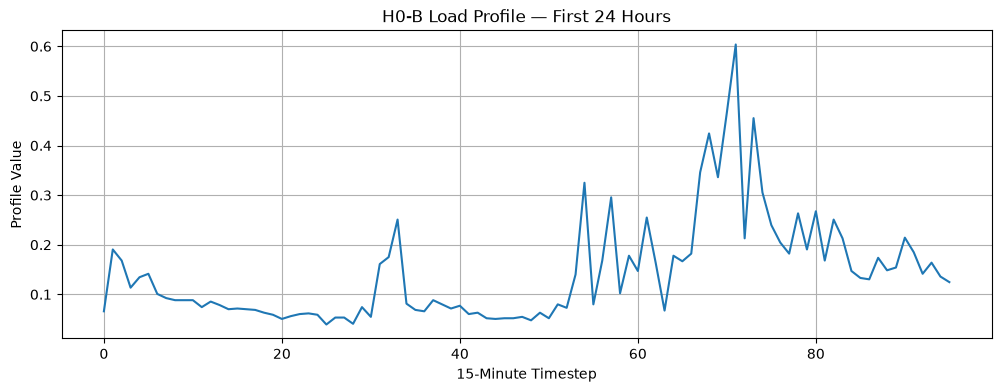

In [37]:
import matplotlib.pyplot as plt  # Plot time-series profiles

h0b = net.profiles["load"]["H0-B_pload"]  # Active-power household load profile

h0b.iloc[:96].plot(figsize=(12, 4))
plt.title("H0-B Load Profile — First 24 Hours")
plt.xlabel("15-Minute Timestep")
plt.ylabel("Profile Value")
plt.grid(True)
plt.show()

In [40]:
pv5 = net.profiles["renewables"]["PV5"]  # PV5 renewable profile

print("First-day minimum :", pv5.iloc[:96].min())
print("First-day maximum :", pv5.iloc[:96].max())
print("Annual minimum    :", pv5.min())
print("Annual maximum    :", pv5.max())
print("Non-zero samples  :", (pv5 > 0).sum())

First-day minimum : 0.0
First-day maximum : 0.0
Annual minimum    : 0.0
Annual maximum    : 0.60263116
Non-zero samples  : 13269


In [41]:
renewables = net.profiles["renewables"]

nonzero_rows = renewables.index[
    renewables["PV5"] > 0
]  # Find timesteps with PV generation

print("First non-zero row:", nonzero_rows[0])
print(
    "Time:",
    renewables.loc[nonzero_rows[0], "time"]
)

First non-zero row: 129
Time: 02.01.2016 08:15


In [42]:
peak_index = pv5.idxmax()  # Find strongest PV5 generation point
day_start = (peak_index // 96) * 96  # Start of that 24-hour day

print("Peak row:", peak_index)
print("Peak PV5:", pv5.loc[peak_index])
print("Day starts at:", renewables.loc[day_start, "time"])

Peak row: 13868
Peak PV5: 0.60263116
Day starts at: 24.05.2016 01:00


C:\Users\sujit\AppData\Local\Temp\ipykernel_3528\1525643441.py:3: Pandas4Warning: The copy keyword is deprecated and will be removed in a future version. Copy-on-Write is active in pandas since 3.0 which utilizes a lazy copy mechanism that defers copies until necessary. Use .copy() to make an eager copy if necessary.
  pv_day.plot(figsize=(12, 4))


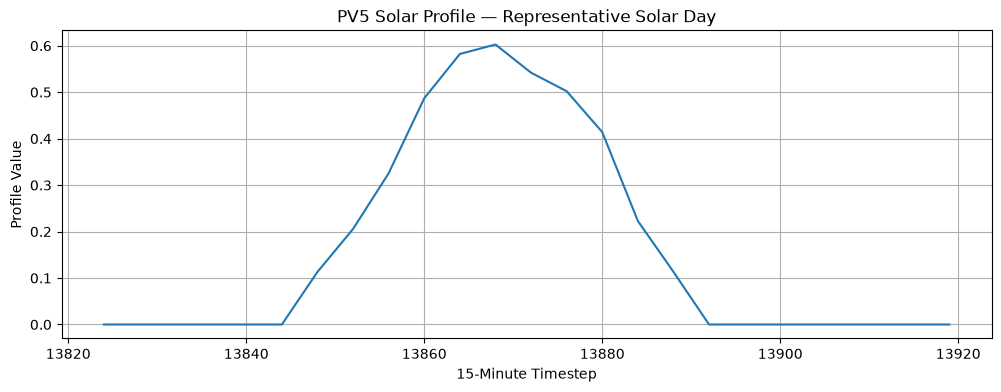

In [43]:
pv_day = pv5.iloc[day_start:day_start + 96]

pv_day.plot(figsize=(12, 4))
plt.title("PV5 Solar Profile — Representative Solar Day")
plt.xlabel("15-Minute Timestep")
plt.ylabel("Profile Value")
plt.grid(True)
plt.show()

In [45]:
h0b = net.profiles["load"]["H0-B_pload"]  # Household active-power profile

load_day = h0b.iloc[day_start:day_start + 96]

load_norm = load_day / load_day.max()  # Normalize load for shape comparison
pv_norm = pv_day / pv_day.max()  # Normalize PV for shape comparison

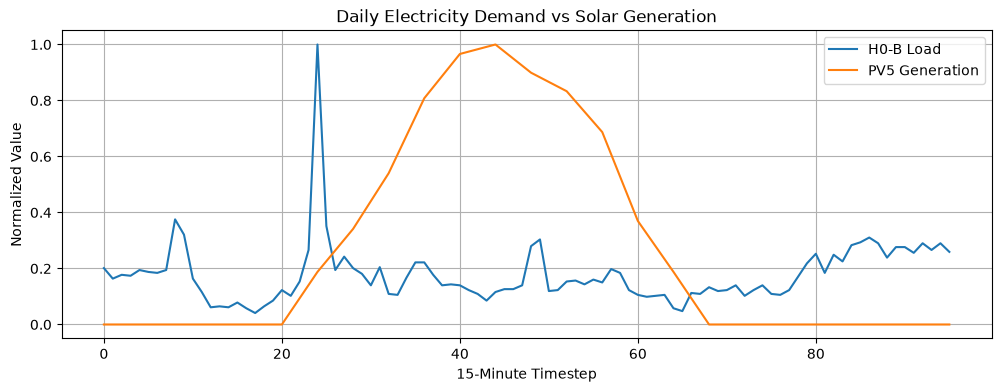

In [46]:
plt.figure(figsize=(12, 4))

plt.plot(load_norm.values, label="H0-B Load")
plt.plot(pv_norm.values, label="PV5 Generation")

plt.title("Daily Electricity Demand vs Solar Generation")
plt.xlabel("15-Minute Timestep")
plt.ylabel("Normalized Value")
plt.legend()
plt.grid(True)
plt.show()

In [47]:
for profile in [f"PV{i}" for i in range(1, 9)]:
    pv = net.profiles["renewables"][profile]

    print(
        profile,
        "| Max:",
        round(pv.max(), 4),
        "| Non-zero:",
        (pv > 0).sum(),
    )

PV1 | Max: 0.6194 | Non-zero: 12787
PV2 | Max: 0.6329 | Non-zero: 12970
PV3 | Max: 0.6164 | Non-zero: 13047
PV4 | Max: 0.6339 | Non-zero: 13126
PV5 | Max: 0.6026 | Non-zero: 13269
PV6 | Max: 0.5953 | Non-zero: 13129
PV7 | Max: 0.5912 | Non-zero: 12373
PV8 | Max: 0.5882 | Non-zero: 12642


In [48]:
load_abs = sb.get_absolute_profiles_from_relative_profiles(
    net,
    element="load",
    multiplying_column="p_mw",
    profile_suffix="_pload",
    time_as_index=True,
)  # Convert relative load profiles into MW values

print("Absolute load profile shape:", load_abs.shape)

Absolute load profile shape: (35136, 11542)


In [49]:
renew_abs = sb.get_absolute_profiles_from_relative_profiles(
    net,
    element="sgen",
    multiplying_column="p_mw",
    time_as_index=True,
)  # Convert renewable profiles into actual MW generation

print("Absolute renewable shape:", renew_abs.shape)

Absolute renewable shape: (35136, 806)


In [50]:
total_load_mw = load_abs.sum(axis=1)  # Sum all 11,542 loads
total_renew_mw = renew_abs.sum(axis=1)  # Sum all 806 generators

print("Peak total load:", total_load_mw.max(), "MW")
print("Peak renewable generation:", total_renew_mw.max(), "MW")

Peak total load: 20.625463088999073 MW
Peak renewable generation: 7.716132499660917 MW


In [51]:
peak_index = total_renew_mw.argmax()  # Highest renewable timestep
day_start = (peak_index // 96) * 96  # Start of that day

load_day = total_load_mw.iloc[day_start:day_start + 96]
renew_day = total_renew_mw.iloc[day_start:day_start + 96]

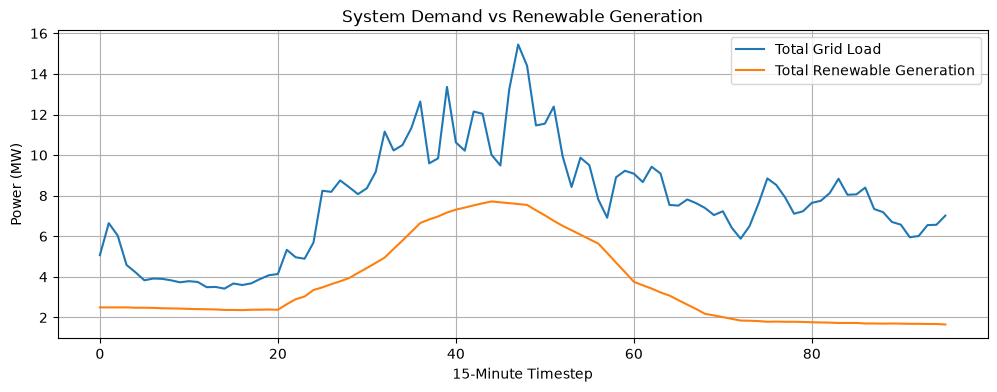

In [52]:
plt.figure(figsize=(12, 4))

plt.plot(load_day.values, label="Total Grid Load")
plt.plot(renew_day.values, label="Total Renewable Generation")

plt.title("System Demand vs Renewable Generation")
plt.xlabel("15-Minute Timestep")
plt.ylabel("Power (MW)")
plt.legend()
plt.grid(True)
plt.show()